<a href="https://colab.research.google.com/github/Yuly-DA/analaysis_everpeak/blob/main/S5_ladb_mobility_economy_project_student_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Introducción

El objetivo es **evaluar cómo la movilidad urbana se relaciona con la productividad económica en las principales ciudades latinoamericanas**.
Se trabaja con datos reales de TomTom Traffic Index y OECD Cities.

## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de ambos datasets**.
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯Objetivo:**
Importar las librerías necesarias, cargar los archivos CSV en DataFrames y realizar una revisión preliminar para entender su contenido.

**Instrucciones:**
- Importa las librerías `pandas`, `numpy`, `seaborn` y `matplotlib.pyplot`.
- Carga los archivos usando `pd.read_csv()`:
  - `'/datasets/tomtom_traffic.csv'`
  - `/datasets/oecd_city_economy.csv` `.
- Guarda los DataFrames en las variables `traffic` y `eco`.
- Muestra las primeras 5 filas de cada DataFrame.


In [ ]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# cargar archivos
traffic = pd.read_csv('/datasets/tomtom_traffic.csv')
eco = pd.read_csv('/datasets/oecd_city_economy.csv')

In [ ]:
# mostrar las primeras 5 filas de traffic
traffic.head(5)

,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232
3,ARE,abu-dhabi,2025-01-13 01:46:30.001,8.2,2.0,4.1,2.0,2.0,2025-01-06 01:46:30.000,7.723808,7.899046,-0.175238
4,ARE,abu-dhabi,2025-01-13 00:01:30.000,1.1,1.0,0.2,1.0,1.0,2025-01-06 00:01:30.000,8.336363,8.604379,-0.268016


In [ ]:
# mostrar las primeras 5 filas de eco
eco.head(5)

,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"
3,2023,brasilia,Brazil,"15.999,00",8.3%,"13,50","4,70"
4,2023,salvador,Brazil,"8.761,00",13.1%,"16,00","3,90"


In [ ]:
# Examinar la estructura de traffic
traffic.info()
traffic.head(3)



eco.info()
eco.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   Country                         1004464 non-null  object 
 1   City                            1004464 non-null  object 
 2   UpdateTimeUTC                   1004464 non-null  object 
 3   JamsDelay                       1004464 non-null  float64
 4   TrafficIndexLive                1004464 non-null  float64
 5   JamsLengthInKms                 1004464 non-null  float64
 6   JamsCount                       1004464 non-null  float64
 7   TrafficIndexWeekAgo             1004464 non-null  float64
 8   UpdateTimeUTCWeekAgo            1004464 non-null  object 
 9   TravelTimeLivePer10KmsMins      1004464 non-null  float64
 10  TravelTimeHistoricPer10KmsMins  1004464 non-null  float64
 11  MinsDelay                       1004464 non-null  float64
dtype

,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"


En la estructura del DF traffic, se observa que:
- Contiene 1.004.464 registros y 12 columnas, de las cuales 8 son de tipo float64 y 4 son de tipo object.
- Las columnas UpdateTimeUTC y UpdateTimeUTCWeekAgo son tipo objetc, pero se requiere convertir a datatime64
- No se evidencian valores nulos.
En la estructura del DF eco, se observa que:
- Contiene 30 registros y 7 columnas, de las cuales 6 son de tipo objetc y 1 int64
- Las columnas City GDP/capita, Unemployment %, PM2.5(μg/m³) y Population (M) son tipo objetc, pero requieren convertirse a float64, ya que representa información cuantitativa
- No se evidencian valores nulos

In [ ]:
 # Estandarizar los nombres de las columnas de traffic
traffic=traffic.rename(columns={"Country":"country","City":"city","UpdateTimeUTC":"update_time_utc","JamsDelay":"jams_delay","TrafficIndexLive":"traffic_index_live","JamsLengthInKms":"jams_length_kms","JamsCount":"jams_count","TrafficIndexWeekAgo":"traffic_index_week_ago","UpdateTimeUTCWeekAgo":"update_time_utc_week_ago","TravelTimeLivePer10KmsMins":"travel_time_live_per_10kms_mins","TravelTimeHistoricPer10KmsMins":"travel_time_historic_per_10kms_mins","MinsDelay":"mins_delay"})

# verificar cambios
traffic.columns



Index(['country', 'city', 'update_time_utc', 'jams_delay',
       'traffic_index_live', 'jams_length_kms', 'jams_count',
       'traffic_index_week_ago', 'update_time_utc_week_ago',
       'travel_time_live_per_10kms_mins',
       'travel_time_historic_per_10kms_mins', 'mins_delay'],
      dtype='object')

In [ ]:

# Estandarizar los nombres de las columnas de eco
eco=eco.rename(columns={"Year":"year", "City":"city","Country":"country","City GDP/capita":"city_gdp_capita","Unemployment %":"unemployment_pct","PM2.5 (μg/m³)":"pm25","Population (M)":"population_m"})

# verificar cambios
eco.columns


Index(['year', 'city', 'country', 'city_gdp_capita', 'unemployment_pct',
       'pm25', 'population_m'],
      dtype='object')

In [ ]:
# Convertir las columnas de traffic a tipo fecha con pd.to_datetime()
traffic['update_time_utc'] = pd.to_datetime(traffic["update_time_utc"],errors="coerce")
traffic['update_time_utc_week_ago'] = pd.to_datetime(traffic["update_time_utc_week_ago"],errors="coerce")

# verificar el cambio
traffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                               Non-Null Count    Dtype         
---  ------                               --------------    -----         
 0   country                              1004464 non-null  object        
 1   city                                 1004464 non-null  object        
 2   update_time_utc                      1004464 non-null  datetime64[ns]
 3   jams_delay                           1004464 non-null  float64       
 4   traffic_index_live                   1004464 non-null  float64       
 5   jams_length_kms                      1004464 non-null  float64       
 6   jams_count                           1004464 non-null  float64       
 7   traffic_index_week_ago               1004464 non-null  float64       
 8   update_time_utc_week_ago             1004464 non-null  datetime64[ns]
 9   travel_time_live_per_10kms_mins      1004464 non-null  fl

In [ ]:
eco.columns
# Limpia separadores y convierte columnas numéricas en eco

eco['city_gdp_capita']=eco['city_gdp_capita'].astype(str).str.replace('.','').str.replace(',', '.').astype(float)
eco['unemployment_pct'] =eco['unemployment_pct'].astype(str).str.replace('%','').str.replace(',', '.').astype(float)
eco['population_m'] = eco['population_m'].astype(str).str.replace(',', '.').astype(float)

# Calcula la población total en unidades absolutas (Multiplica * 1000000)
eco['population']=eco['population_m']* 1000000

# verificar el cambio
eco.info()
eco.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   year              30 non-null     int64  
 1   city              30 non-null     object 
 2   country           30 non-null     object 
 3   city_gdp_capita   30 non-null     float64
 4   unemployment_pct  30 non-null     float64
 5   pm25              30 non-null     object 
 6   population_m      30 non-null     float64
 7   population        30 non-null     float64
dtypes: float64(4), int64(1), object(3)
memory usage: 2.0+ KB


,year,city,country,city_gdp_capita,unemployment_pct,pm25,population_m,population
0,2023,buenos-aires,Argentina,15782.0,6.2,"15,2",15.3,15300000.0
1,2023,sao-paulo,Brazil,14475.0,9.1,"29,50",22.5,22500000.0
2,2023,rio-de-janeiro,Brazil,13142.0,9.8,"19,10",13.6,13600000.0


In [ ]:
# Extraer el año de las fechas en update_time_utc
traffic['year'] = traffic['update_time_utc'].dt.year

# Verificar cambio
traffic.head(3)

,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_kms,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10kms_mins,travel_time_historic_per_10kms_mins,mins_delay,year
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437,2025
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635,2025
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232,2025


In [ ]:
# Filtra los registros del año 2024
traffic_2024 = traffic[traffic['year'] == 2024].copy()
eco_2024 = eco[eco['year'] == 2024].copy()

# Revisar dataframes nuevos
display(traffic_2024.head())
display(eco_2024.head())


,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_kms,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10kms_mins,travel_time_historic_per_10kms_mins,mins_delay,year
302,ARE,abu-dhabi,2024-12-31 23:01:30.000,12.9,5.0,2.5,5.0,2.0,2024-12-24 23:01:30.001,8.560399,8.519634,0.040765,2024
303,ARE,abu-dhabi,2024-12-31 22:01:30.000,136.0,21.0,20.6,32.0,3.0,2024-12-24 22:01:30.000,10.355732,9.049445,1.306286,2024
304,ARE,abu-dhabi,2024-12-31 21:16:30.000,455.2,31.0,40.4,72.0,4.0,2024-12-24 21:01:30.000,11.456878,9.305174,2.151704,2024
305,ARE,abu-dhabi,2024-12-31 20:01:00.001,399.4,27.0,38.0,75.0,6.0,2024-12-24 20:01:30.001,11.670062,9.952811,1.717252,2024
306,ARE,abu-dhabi,2024-12-31 19:46:00.000,366.4,28.0,39.8,82.0,9.0,2024-12-24 19:01:00.000,11.686322,10.008469,1.677853,2024


,year,city,country,city_gdp_capita,unemployment_pct,pm25,population_m,population
15,2024,buenos-aires,Argentina,18117.0,7.2,"14,50",15.4,15400000.0
16,2024,sao-paulo,Brazil,14703.0,8.5,"28,00",22.6,22600000.0
17,2024,rio-de-janeiro,Brazil,13349.0,9.2,"18,40",13.7,13700000.0
18,2024,brasilia,Brazil,16251.0,7.8,"12,80",4.8,4800000.0
19,2024,salvador,Brazil,8899.0,12.4,"15,20",3.9,3900000.0


In [ ]:
# Calcular los  promedios de trafico por ciudad, país y año
traffic_city_year_2024 = (traffic_2024
    .groupby(['city', 'country', 'year'])[['jams_delay', 'traffic_index_live','jams_length_kms','jams_count','mins_delay',
    'travel_time_live_per_10kms_mins','travel_time_historic_per_10kms_mins']].agg('mean')
    .reset_index())

# Mostrar resultado
traffic_city_year_2024.head()

,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_historic_per_10kms_mins
0,a-coruna,ESP,2024,17.935187,15.259774,2.198002,4.934405,0.774172,16.267977,15.493804
1,aachen,DEU,2024,26.732141,20.960314,3.892586,6.601832,0.792968,13.397861,12.604894
2,aarhus,DNK,2024,21.200616,16.575891,2.736736,6.109987,0.495276,15.219292,14.724016
3,abu-dhabi,ARE,2024,171.157315,13.902028,24.507380,47.268019,0.139764,9.829092,9.689328
4,adana,TUR,2024,83.864761,22.541040,11.827331,23.754620,1.129749,15.879694,14.749945


In [ ]:
traffic_city_year_2024.sort_values(["jams_delay"], ascending=False)

,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_historic_per_10kms_mins
221,mexico-city,MEX,2024,2833.057892,34.218190,389.239265,594.969392,1.855542,21.809092,19.953550
352,tokyo,JPN,2024,2152.574357,36.805059,373.069734,518.809420,0.698152,22.443778,21.745626
246,new-york,USA,2024,2133.400000,28.210388,398.227892,544.474902,1.396351,18.505043,17.108691
200,london,GBR,2024,2050.703662,29.230166,287.632868,471.795554,1.325160,17.714139,16.388979
211,manila,PHL,2024,1741.493381,66.129402,246.858082,341.881205,2.469894,27.134629,24.664734
...,...,...,...,...,...,...,...,...,...,...
111,dunedin,NZL,2024,4.651175,15.430809,0.712315,1.591384,0.633294,16.226009,15.592715
363,uppsala,SWE,2024,4.194486,13.939168,0.656368,1.349672,0.501802,15.746717,15.244916
123,fujairah,ARE,2024,4.025959,10.907719,0.731910,1.373006,0.194951,11.662590,11.467639
12,almere,NLD,2024,3.633523,6.290478,0.506362,1.064063,-0.017544,9.467150,9.484694


La ciudad con el mayor tiempo promedio de tráfico es México

In [ ]:
# Seleccionar columnas clave de tráfico y economía
left_cols = ['city','country','year','jams_delay','traffic_index_live',
             'jams_length_kms','jams_count','mins_delay',
             'travel_time_live_per_10kms_mins','travel_time_historic_per_10kms_mins']

right_cols = ['city','year','city_gdp_capita','unemployment_pct','pm25','population']

# Usar .copy() para crear los dos nuevos datasets reducidos
traffic_2024_small = traffic_city_year_2024[left_cols].copy()
eco_2024_small = eco_2024[right_cols].copy()

# Unir datasets
merged = pd.merge(traffic_2024_small, eco_2024_small,
                  on=['city', 'year'], how='inner')

# Mostrar las primeras 5 filas
merged.head()

,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_historic_per_10kms_mins,city_gdp_capita,unemployment_pct,pm25,population
0,belo-horizonte,BRA,2024,263.047879,19.428946,44.038129,68.805422,0.487228,18.304538,17.817311,11124.0,9.5,"16,80",6100000.0
1,bogota,COL,2024,1141.552364,37.614273,140.893564,230.566550,1.699628,24.992185,23.292557,11442.0,10.0,"17,60",11300000.0
2,brasilia,BRA,2024,101.576326,11.258220,18.337133,27.280140,0.193442,13.338658,13.145216,16251.0,7.8,"12,80",4800000.0
3,buenos-aires,ARG,2024,571.089593,17.756012,100.287844,137.359860,0.416566,17.907916,17.491349,18117.0,7.2,"14,50",15400000.0
4,curitiba,BRA,2024,183.469274,14.954545,30.050044,46.898164,0.139965,17.258700,17.118736,12381.0,8.2,"13,50",3700000.0


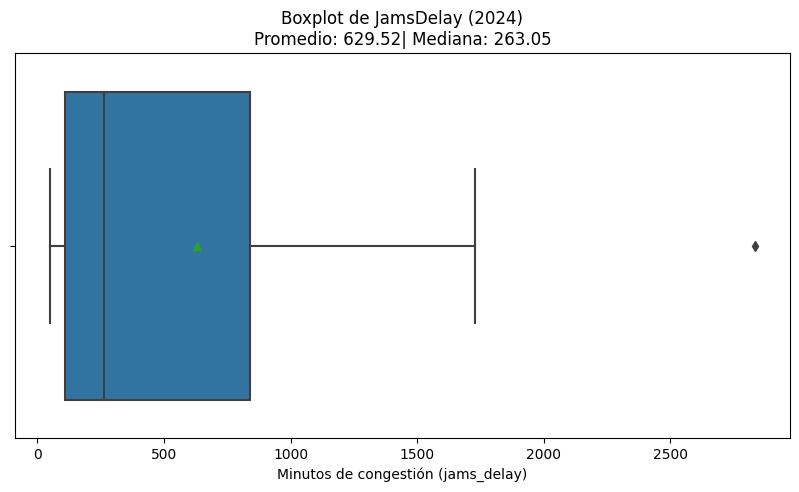

In [ ]:
# Crear boxplot para observar el comportamiento de los minutos de congestion JamsDelay
plt.figure(figsize=(10, 5))
sns.boxplot(x=merged['jams_delay'], showmeans=True)
plt.xlabel('Minutos de congestión (jams_delay)')

# obtener promedio para mostrarlo en título
mean_value = merged['jams_delay'].mean()
median_value = merged['jams_delay'].median()
plt.title(f'Boxplot de JamsDelay (2024)\nPromedio: {mean_value:.2f}| Mediana: {median_value:.2f}')
plt.show()

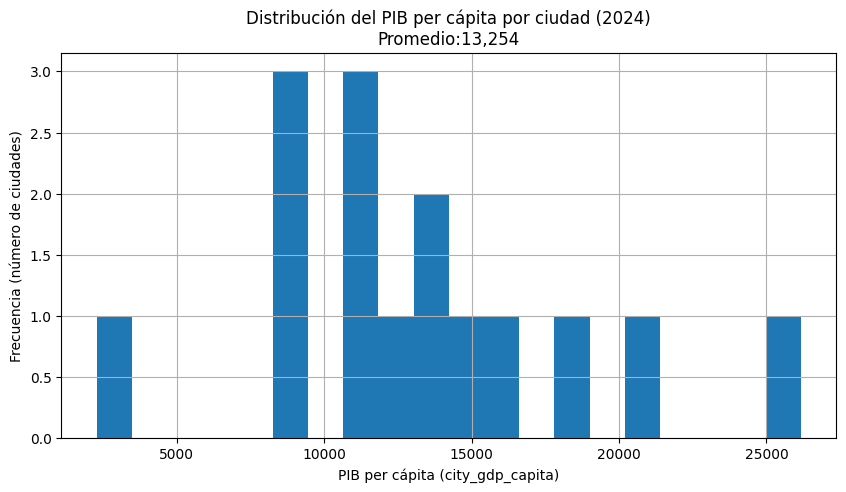

In [ ]:
# Crear histograma para ver la distribución de la economía (city_gdp_capita)
merged['city_gdp_capita'].hist(bins=20, figsize=(10, 5))

# Línea con el valor promedio del PIB per cápita
mean_gdp = merged['city_gdp_capita'].mean()
plt.title(f'Distribución del PIB per cápita por ciudad (2024)\nPromedio:{mean_gdp:,.0f}')
plt.xlabel('PIB per cápita (city_gdp_capita)')
plt.ylabel('Frecuencia (número de ciudades)')
plt.show()

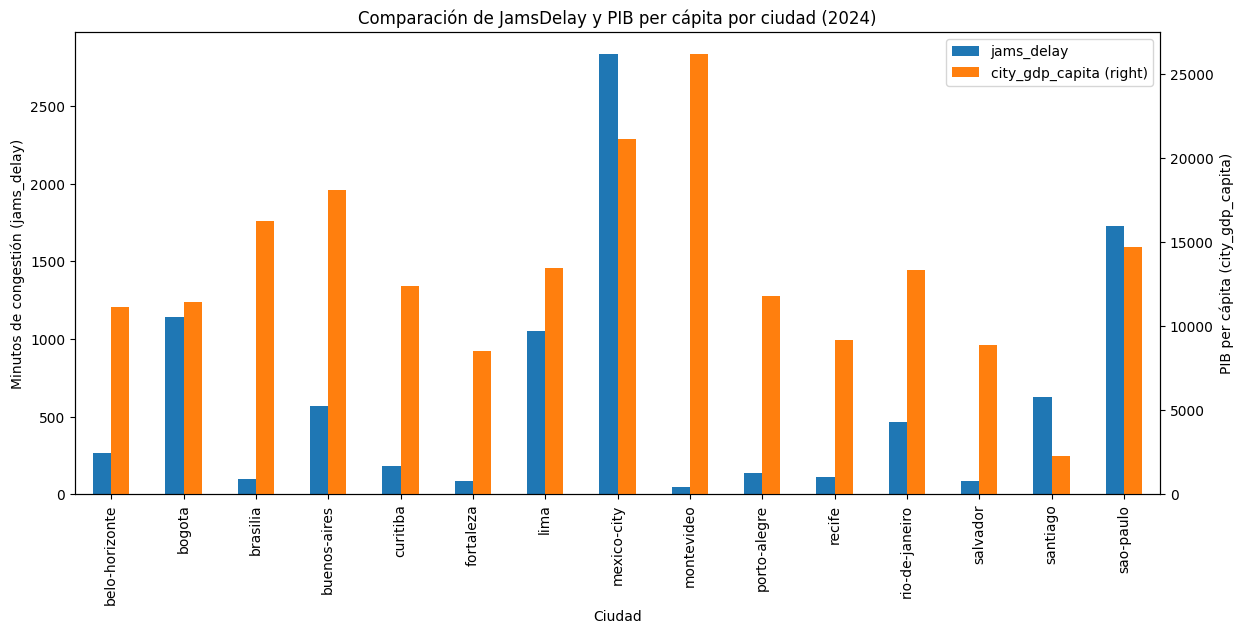

In [ ]:

# Gráfico de barras para comparar jams_delay y city_gdp_capita por ciudad
ax = merged.plot(x='city', kind='bar', y=['jams_delay', 'city_gdp_capita'],
                 secondary_y='city_gdp_capita', figsize=(14, 6), rot=90)
plt.title('Comparación de JamsDelay y PIB per cápita por ciudad (2024)')
ax.set_xlabel('Ciudad')
ax.set_ylabel('Minutos de congestión (jams_delay)')
ax.right_ax.set_ylabel('PIB per cápita (city_gdp_capita)')
plt.show()


1. Frente a la gráfica Boxplot:
- La media (629.52 minutos) es mucho mayor que la mediana (263.05 minutos). Esto indica que la distribución está sesgada
a la derecha: la mayoría de las ciudades tiene poca congestión, pero unas pocas con valores muy altos suben el promedio.
- La mitad de las ciudades tiene menos de unos 263 minutos de congestión, y la caja muestra que la mayoría está aproximadamente entre 100 y 840 minutos.
- Hay un valor atípico que supera los 2,500 minutos.
2. Frente al gráfico Hisograma:
- El promedio es de 13,254, y la mayoría de las ciudades se concentra entre 8,000 y 16,000.
Hay dos valores extremos: una ciudad con PIB muy bajo (unos 2,300, que según el gráfico de barras es Santiago) y una con PIB muy alto (unos 26,000, Montevideo).
3. Frente al gráfico de barras
¿Las ciudades con mayor PIB per cápita también presentan más congestión? No se observa una relación clara entre el PIB per cápita y la congestión. Hay ciudades que cumplen la idea de “más riqueza, más tráfico”, como Ciudad de México, pero también hay casos contrarios: Montevideo tiene el PIB más alto y la menor congestión, y Santiago tiene el PIB más bajo pero una congestión media. Además, Bogotá, Lima y São Paulo tienen mucha congestión con un PIB intermedio.

Las ciudades con más congestión (Ciudad de México, São Paulo, Bogotá y Lima) tienen en común que son ciudades muy grandes y muy pobladas, más que tener un PIB alto. Por eso, el tamaño de la población podría explicar mejor la congestión que el PIB per cápita.

In [ ]:
# Exporta el dataset final como CSV
merged.to_csv("ladb_mobility_economy_2024_clean.csv", index=False)


---

## ✅ Entregables

1. **Notebook `.ipynb`** con todas las celdas (código + comentarios).
2. **CSV final**: `ladb_mobility_economy_2024_clean.csv`.
3. **Resumen ejecutivo breve** en Markdown (3–5 párrafos).



---

# 🧾 Resumen ejecutivo (plantilla)


**Contexto & objetivo:**  
- ¿qué relación existe entre la movilidad urbana (congestión, tiempos de viaje) y la productividad económica (PIB per cápita)?
Para responder a esta pregunta se utilizaron variables de tráfico como los minutos de congestión (jams_delay), el índice de tráfico (traffic_index_live) y los tiempos de viaje por cada 10 km. Para la productividad económica se utilizó el PIB per cápita (city_gdp_capita), acompañado de la población, el desempleo y la calidad del aire (pm25).

**Cobertura de datos:**  
El análisis se centró en el año 2024 e incluyó 15 ciudades y 7 países: Brasil, Colombia, Perú, México, Argentina, Chile y Uruguay.

**Metodología (alto nivel):**  
  1. Limpieza de los datos: se revisó los formatos de las columnas, estandarización de los nombres y se filtró por el año 2024.
  2. Agrupación de los datos de tráfico por ciudad y año para tener una sola fila por ciudad.
  3. Unión de tabla tráfico con la de indicadores económicos usando city y year como claves y una unión INNER, para dejar solo las ciudades presentes en ambos datasets.
  4. Validación de los datos con gráficos: un boxplot para la congestión, un histograma para el PIB per cápita y un gráfico de barras para comparar ambas variables por ciudad.
  5. Exportación del dataset a archivo .csv

**Hallazgos iniciales:**  
- La congestión está distribuida de forma desigual.
- La media (629 minutos) es más del doble de la mediana (263 minutos), lo que indica que unas pocas ciudades con mucho tráfico suben el promedio.
- Ciudad de México aparece como valor atípico, con unos 2,800 minutos de congestión.
- El PIB per cápita promedio es de 13,254 y la mayoría de las ciudades está entre 8,000 y 16,000.
- La relación entre PIB per cápita y congestión no es tan evidente, ya que por ejemplo Ciudad de México tiene mucho tráfico y un PIB alto, pero Montevideo tiene el PIB más alto con la menor congestión, y Bogotá, Lima y São Paulo tienen mucha congestión con un PIB intermedio.
- Las ciudades más congestionadas tienen en común que son ciudades muy grandes, así que la población podría explicar mejor el tráfico que el PIB.
- Revisar la anomalía en la ciudad de Santiago, ya que aparece con un PIB per cápita muy bajo (unos 2,300).

**Recomendaciones**  
Bogotá debería ser una ciudad prioritaria para inversión en infraestructura de transporte. Combina una congestión alta (unos 1,140 minutos) con un PIB per cápita por debajo del promedio (unos 11,400), es decir, mucho tráfico con menor productividad económica.
Lima muestra un patrón parecido, pero menos marcado. Y Buenos Aires tiene congestión moderada y un PIB alto, así que no sería una ciudad para priorizar.

- Sería interesante incluir la población para mirar si puede ser un factor explicativo. Al igual que revisar otros años para ver si hay tendencias en el tiempo.
- Es importante validar la fuente de datos de Santiago antes de sacar conclusiones sobre esa ciudad.
